# 0. OUTRIDER Comparison
- Posterior predictive check (PPC) of the NM engine vs OUTRIDER on the HC CV folds.
- Removed on 2026-10-01: gene-coverage and CV Z-score-moment sections.
  - They read `gene_coverage_by_expression.csv`, `outrider_coverage_summary.json` and `outrider_cv_metrics.csv`, which no script in this repo produces.
  - After the 2026-09-30 batch redefinition they would have mixed 2026-08 pre-refit numbers into an otherwise post-refit notebook.
  - Rebuild the producers before restoring them.

In [1]:
%load_ext autoreload
%autoreload 2

import os
import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

os.environ["NM_PIPELINE"] = "p3"
sys.path.insert(0, str(Path.cwd().parents[1]))
import MixedEffectsModeling.config as config
from viz_style import apply_style
apply_style()

import json

OC = config.OUTRIDER_COMPARISON_DIR
pd.set_option("display.width", 120)


## 1. CV posterior predictive check (PPC)
- Observed vs model-implied mean / std / zero fraction.

In [2]:
eng_ppc = pd.read_csv(config.CV_DIR / "cv_calibration_moments.csv").set_index("gene")
outr_ppc = pd.read_csv(OC / "outrider_cv_calibration_moments.csv").set_index("gene")

common_ppc_genes = eng_ppc.index.intersection(outr_ppc.index)
print(f"our engine PPC genes: {len(eng_ppc)} | OUTRIDER PPC genes: {len(outr_ppc)} | common: {len(common_ppc_genes)}")

eng_ppc_full = eng_ppc.median()
eng_ppc_sub = eng_ppc.loc[common_ppc_genes].median()
outr_ppc_med = outr_ppc.median()
ppc_table = pd.DataFrame({
    "our_engine (all genes)": eng_ppc_full.reindex(["obs_mean","pred_mean","obs_var","pred_var","obs_zero","pred_zero"]).values,
    "our_engine (OUTRIDER genes)": eng_ppc_sub.reindex(["obs_mean","pred_mean","obs_var","pred_var","obs_zero","pred_zero"]).values,
    "outrider": outr_ppc_med.reindex(["obs_mean","pred_mean","obs_var","pred_var","obs_zero","pred_zero"]).values,
}, index=["mean (obs)", "mean (pred)", "std (obs)", "std (pred)", "zero-frac (obs)", "zero-frac (pred)"])
ppc_table


our engine PPC genes: 19914 | OUTRIDER PPC genes: 12356 | common: 12346


,our_engine (all genes),our_engine (OUTRIDER genes),outrider
mean (obs),32.169764,121.595439,121.483953
mean (pred),35.166144,122.529890,127.295338
std (obs),72.329432,182.401309,182.258602
std (pred),106.701923,214.469486,226.189892
zero-frac (obs),0.221284,0.055743,0.055743
zero-frac (pred),0.187483,0.034041,0.018670


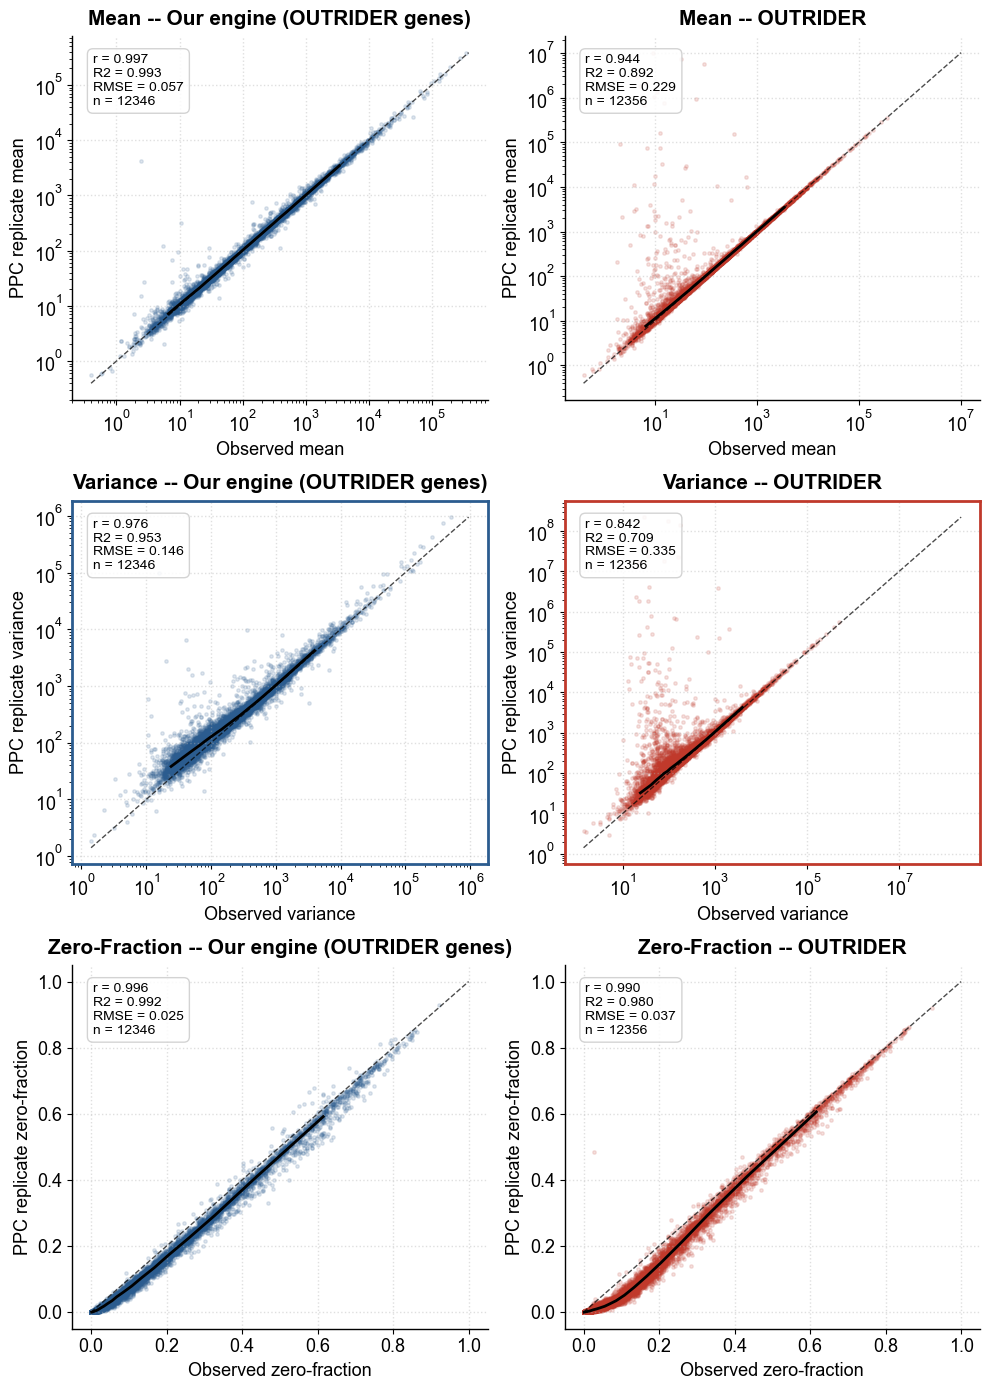

In [3]:
from MixedEffectsModeling.validation.ppc_simulate import binned_medians, calib_stats

eng_sub_cal = pd.read_csv(OC / "our_engine_cv_calibration_moments_outrider_genes.csv")
outr_cal = pd.read_csv(OC / "outrider_cv_calibration_moments.csv")

panels = [("obs_mean", "pred_mean", "Mean", True), ("obs_var", "pred_var", "Variance", True),
         ("obs_zero", "pred_zero", "Zero-Fraction", False)]
engines = [("Our engine (OUTRIDER genes)", eng_sub_cal, "#2b5c8f"), ("OUTRIDER", outr_cal, "#c0392b")]

fig, axes = plt.subplots(3, 2, figsize=(10, 14))

for row, (oc, pc, title_str, logsc) in enumerate(panels):
    xlim = None
    for col, (eng_label, cal, color) in enumerate(engines):
        ax = axes[row, col]
        ax.scatter(cal[oc], cal[pc], s=6, alpha=0.15, color=color)
        bx, by = binned_medians(cal[oc], cal[pc])
        ax.plot(bx, by, '-', color='black', linewidth=2)

        if logsc:
            lo = max(min(cal[oc].min(), cal[pc].min()), 1e-3)
            hi = max(cal[oc].max(), cal[pc].max())
            ax.plot([lo, hi], [lo, hi], 'k--', linewidth=1, alpha=0.7)
            ax.set_xscale('log'); ax.set_yscale('log')
        else:
            ax.plot([0, 1], [0, 1], 'k--', linewidth=1, alpha=0.7)

        cs = calib_stats(cal[oc], cal[pc], logsc)
        ax.set_title(f"{title_str} -- {eng_label}", fontweight='bold', pad=8)
        ax.set_xlabel(f'Observed {title_str.lower()}')
        ax.set_ylabel(f'PPC replicate {title_str.lower()}')
        stats_text = "r = {pearson_r:.3f}\nR2 = {r2:.3f}\nRMSE = {rmse:.3f}\nn = {n}".format(**cs)
        ax.text(0.05, 0.95, stats_text, transform=ax.transAxes, fontsize=10, verticalalignment='top',
                bbox=dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.85, edgecolor='#cccccc'))
        ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
        ax.grid(True, linestyle=':', alpha=0.4)
        if row == 1:
            for spine in ax.spines.values():
                spine.set_visible(True)
                spine.set_edgecolor('#c0392b' if col == 1 else '#2b5c8f')
                spine.set_linewidth(2)

plt.tight_layout()
fig.savefig(OC / 'Figures' / 'ppc_scatter_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

### 1a. Gene-level calibration statistics
- Pearson r / R2, Spearman rho, RMSE, MAE.

In [4]:
calib = pd.read_csv(OC / "ppc_calib_stats.csv")
calib_wide = calib.pivot(index="panel", columns="engine",
                         values=["pearson_r", "r2", "spearman_rho", "rmse", "mae"])
calib_wide = calib_wide.reindex(["mean", "var", "zero_frac"])
calib_wide = calib_wide.reindex(columns=["our_engine_full", "our_engine_outrider_genes", "outrider"], level=1)
calib_wide

pearson_r                                                  r2                                      \
engine    our_engine_full our_engine_outrider_genes  outrider our_engine_full our_engine_outrider_genes  outrider   
panel                                                                                                               
mean             0.969053                  0.996500  0.944434        0.939064                  0.993013  0.891955   
var              0.917219                  0.976230  0.841878        0.841290                  0.953025  0.708759   
zero_frac        0.999129                  0.996223  0.989960        0.998258                  0.992460  0.980020   

             spearman_rho                                                rmse                                      \
engine    our_engine_full our_engine_outrider_genes  outrider our_engine_full our_engine_outrider_genes  outrider   
panel                                                                                                               
mean             0.975118                  0.997299  0.973826        0.257106                  0.057213  0.228979   
var              0.940892                  0.976940  0.918139        0.387526                  0.146163  0.335018   
zero_frac        0.998108                  0.993992  0.988310        0.021342                  0.024554  0.036592   

                      mae                                      
engine    our_engine_full our_engine_outrider_genes  outrider  
panel                                                          
mean             0.058382                  0.026512  0.038831  
var              0.156820                  0.094032  0.110266  
zero_frac        0.015921                  0.019480  0.028555